# Interactive GRN Trajectory Simulator

This notebook allows you to generate biologically realistic Gene Regulatory Networks (GRNs) using a directed Scale-Free topology, simulate their trajectories with heterogeneous kinetics and multiplicative noise, and visualize the results.

In [21]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    x = np.clip(x, -50, 50)
    return 1.0 / (1.0 + np.exp(-x))

In [22]:
def generate_scale_free_W(N, m=2, seed=42):
    """Generates a scale-free directed GRN using directed preferential attachment."""
    np.random.seed(seed)
    W = np.zeros((N, N))
    out_degrees = np.zeros(N)
    
    core_size = m + 1
    for i in range(core_size):
        for j in range(core_size):
            if i != j and np.random.rand() > 0.5:
                sign = np.random.choice([-1, 1])
                mag = np.random.uniform(1.0, 3.0)
                W[i, j] = sign * mag
                out_degrees[j] += 1
                
    for i in range(core_size, N):
        weights = out_degrees[:i] + 1.0
        probs = weights / np.sum(weights)
        regulators = np.random.choice(i, size=m, replace=False, p=probs)
        
        for reg in regulators:
            sign = np.random.choice([-1, 1])
            mag = np.random.uniform(1.0, 3.0)
            W[i, reg] = sign * mag
            out_degrees[reg] += 1
            
    return W

In [ ]:
def simulate_realistic_trajectories(W, T_total, dt, dt_meas, D_base, mean_d, std_d, mean_V, std_V, seed=123):
    N = W.shape[0]
    np.random.seed(seed)
    
    # Heterogeneous parameters (Log-Normal)
    d = np.random.lognormal(mean=np.log(mean_d), sigma=std_d, size=N)
    V = np.random.lognormal(mean=np.log(mean_V), sigma=std_V, size=N)
    
    n_steps = int(T_total / dt)
    x = np.random.uniform(0.1, 10.0, size=N)
    x_history = []
    t_history = []
    
    out_degrees = (W != 0).sum(axis=0)
    hub_node = np.argmax(out_degrees)
    
    meas_step = max(1, int(dt_meas / dt))
    
    for step in range(n_steps):
        t = step * dt
        drift = -d * x + V * sigmoid(W @ x)
        noise = np.sqrt(2 * D_base) * np.random.normal(0, np.sqrt(dt), size=N)
        
        x = x + drift * dt + noise
        x = np.maximum(x, 0.0)
        
        if step % meas_step == 0:
            x_history.append(x.copy())
            t_history.append(t)
            
    return np.array(t_history), np.array(x_history), hub_node, out_degrees

### Global Parameters
Tweak the parameters below to see how they affect the network generation and the resulting dynamics.

In [33]:
# Network Parameters
N = 30              # Number of genes
m = 2               # Edges to attach from a new node to existing nodes
seed_network = 42   # Random seed for network generation

# Simulation Parameters
T_total = 100.0      # Total simulation time
dt = 0.001          # Simulation time step
dt_meas = 0.05      # Measurement interval
D_base = 0.1        # Base multiplicative noise level

# Kinetic Parameters (Mean and Std of Log-Normal distribution)
mean_decay = 0.5    # Average decay rate
std_decay = 0.5     # Heterogeneity in decay rate
mean_V = 2.0        # Average max transcription rate
std_V = 0.5         # Heterogeneity in transcription rate
seed_sim = 123      # Random seed for simulation

In [34]:
# 1. Generate Network
W = generate_scale_free_W(N, m, seed=seed_network)

# 2. Simulate
t, X, hub_node, out_degrees = simulate_realistic_trajectories(
    W, T_total, dt, dt_meas, D_base, 
    mean_decay, std_decay, mean_V, std_V, seed=seed_sim
)

print(f"Master Regulator is Node {hub_node} with {out_degrees[hub_node]} outgoing edges.")

Master Regulator is Node 0 with 16 outgoing edges.


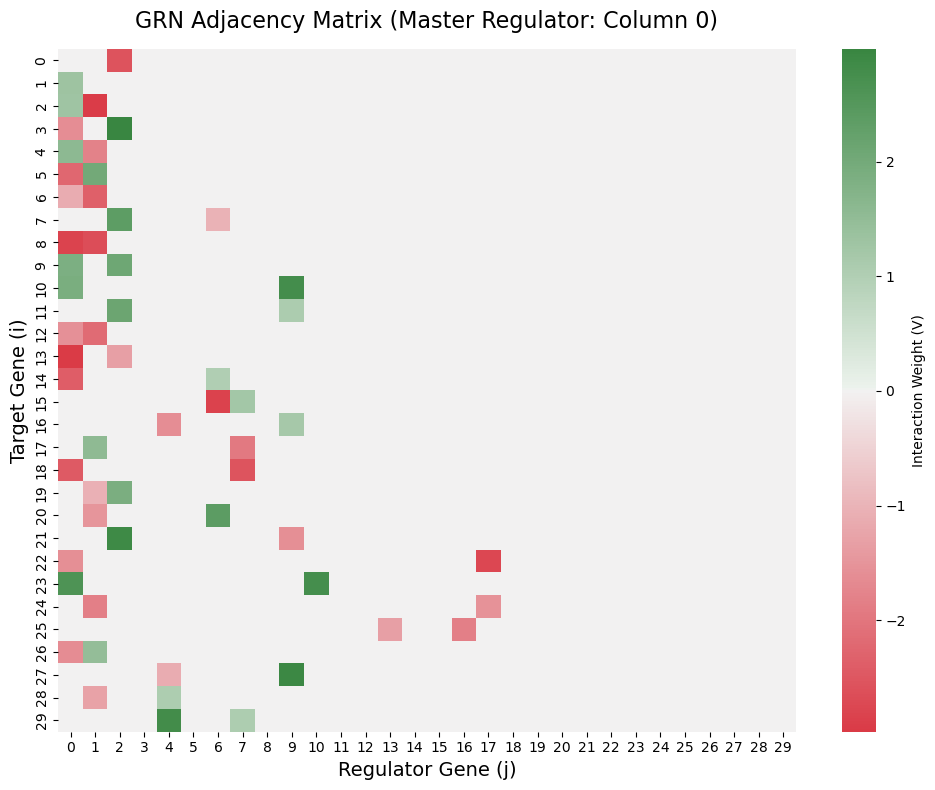

In [35]:
import seaborn as sns

# 4. Visualize the Network as an Adjacency Matrix
plt.figure(figsize=(10, 8))

# W[i, j] represents the effect of gene j on gene i.
# So rows are targets, and columns are regulators.
cmap = sns.diverging_palette(10, 130, as_cmap=True)
sns.heatmap(W, cmap=cmap, center=0, annot=False, 
            cbar_kws={'label': 'Interaction Weight (V)'})

plt.title(f"GRN Adjacency Matrix (Master Regulator: Column {hub_node})", fontsize=16, pad=15)
plt.xlabel("Regulator Gene (j)", fontsize=14)
plt.ylabel("Target Gene (i)", fontsize=14)
plt.tight_layout()
plt.show()

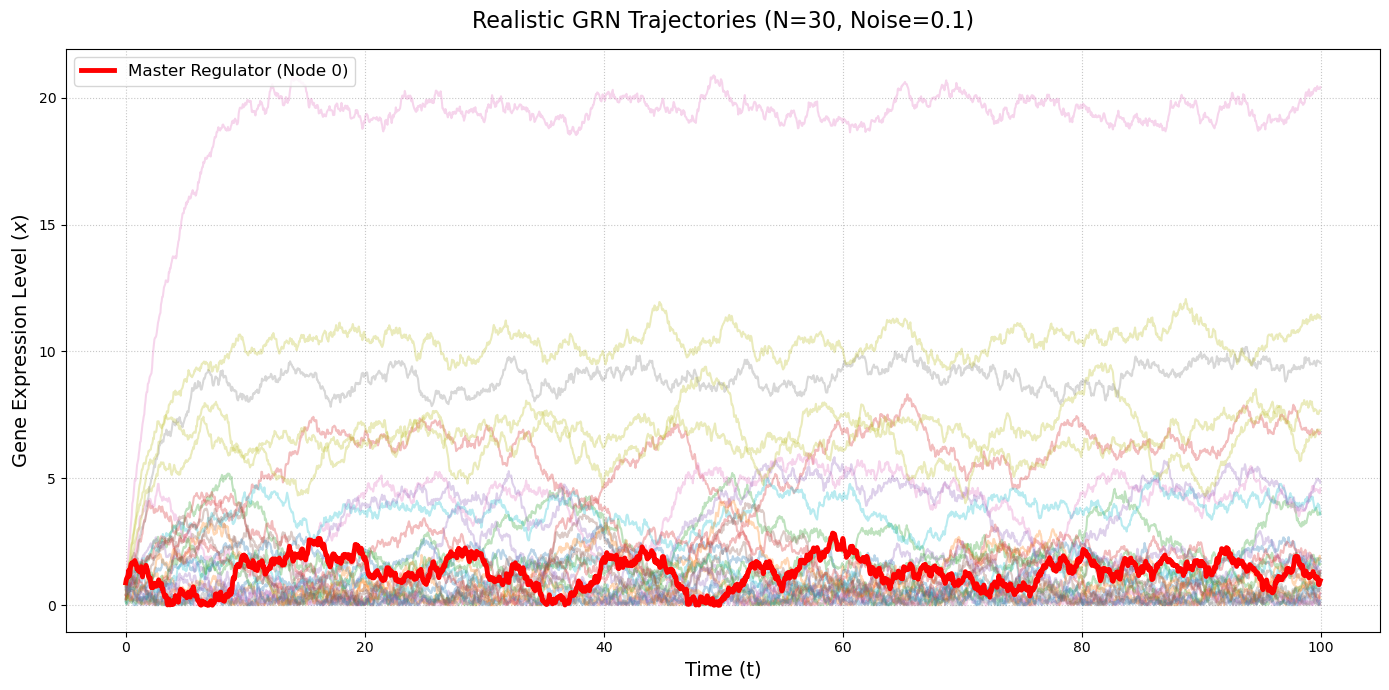

In [36]:
# 3. Plot
plt.figure(figsize=(14, 7))

for i in range(N):
    if i != hub_node:
        plt.plot(t, X[:, i], alpha=0.3, linewidth=1.5)
        
plt.plot(t, X[:, hub_node], color='red', linewidth=3.5, label=f'Master Regulator (Node {hub_node})')

plt.title(f"Realistic GRN Trajectories (N={N}, Noise={D_base})", fontsize=16, pad=15)
plt.xlabel("Time (t)", fontsize=14)
plt.ylabel("Gene Expression Level ($x$)", fontsize=14)
plt.legend(fontsize=12, loc='upper left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()